# Chat sentiment analysis with a local Ollama model

This notebook classifies **chat messages** as `positive`, `negative`, or `neutral` using **Llama 3.2 1B** running on your machine through **Ollama Desktop**.

Run the cells **in order**, one at a time.

## What you need before you start

1. Ollama Desktop is installed and **running** (look for the llama icon in the system tray).
2. The model is pulled. In a terminal:

```text
ollama pull llama3.2:1b
```

3. Python 3.10+ and Jupyter (`pip install jupyter`).

Ollama serves the model at `http://localhost:11434`. Python talks to that API; nothing is sent to the cloud.

## Step 1 — Install Python packages

Run this once. Restart the kernel if Jupyter was already open before the install.

In [1]:
%pip install ollama pandas matplotlib

You should consider upgrading via the 'c:\Users\jahed\AppData\Local\Programs\Python\Python310\python.exe -m pip install --upgrade pip' command.


## Step 2 — Import libraries

In [2]:
import json
from collections import Counter

import pandas as pd
from ollama import chat, list as ollama_list

## Step 3 — Confirm Ollama is running and the model is installed

If this cell fails, start Ollama Desktop and wait a few seconds, then run it again.

The model name must match what `ollama list` shows. The usual tag is `llama3.2:1b`.

In [4]:
MODEL = "llama3.2:1b"

installed = ollama_list()
names = [m.model for m in installed.models]
print("Installed models:")
for name in names:
    print(" -", name)

if MODEL not in names:
    raise SystemExit(
        f"{MODEL!r} is not installed. In a terminal run: ollama pull {MODEL}\n"
        f"If the tag is slightly different, copy it from the list above and set MODEL."
    )

print(f"\nReady to use {MODEL}")

Installed models:
 - deepseek-r1:1.5b
 - llama3.2:1b

Ready to use llama3.2:1b


## Step 4 — Send a first test prompt

This only checks that the local model answers. The next step turns it into structured sentiment labels.

In [5]:
test = chat(
    model=MODEL,
    messages=[{"role": "user", "content": "Reply with one word: hello"}],
)
print(test.message.content)

Hello.


## Step 5 — Sentiment prompt + JSON schema

Small models wander if you ask for free-form text. We:

- give a short system instruction
- ask for JSON only
- pass a JSON schema so Ollama constrains the output
- set `temperature=0` so labels stay stable

In [6]:
SYSTEM_PROMPT = """You classify the sentiment of a chat message.
Choose exactly one label: positive, negative, or neutral.
Judge the speaker's attitude, not the topic.
If mixed or unclear, choose the dominant feeling. If none, use neutral.
Keep reasoning to one short sentence."""

SENTIMENT_SCHEMA = {
    "type": "object",
    "properties": {
        "sentiment": {
            "type": "string",
            "enum": ["positive", "negative", "neutral"],
        },
        "confidence": {
            "type": "number",
            "minimum": 0,
            "maximum": 1,
        },
        "reasoning": {"type": "string"},
    },
    "required": ["sentiment", "confidence", "reasoning"],
}

## Step 6 — Classify one chat message

In [7]:
message = "Thanks, that fix worked perfectly!"

response = chat(
    model=MODEL,
    messages=[
        {"role": "system", "content": SYSTEM_PROMPT},
        {"role": "user", "content": f"Chat message:\n{message}"},
    ],
    format=SENTIMENT_SCHEMA,
    options={"temperature": 0},
)

print("Raw model output:")
print(response.message.content)

result = json.loads(response.message.content)
print("\nParsed:")
print(" sentiment :", result["sentiment"])
print(" confidence:", result["confidence"])
print(" reasoning :", result["reasoning"])

Raw model output:
{"sentiment": "positive", "confidence": 0.8, "reasoning": "The speaker uses the word 'thanks' and the phrase 'worked perfectly', indicating a strong positive sentiment."}

Parsed:
 sentiment : positive
 confidence: 0.8
 reasoning : The speaker uses the word 'thanks' and the phrase 'worked perfectly', indicating a strong positive sentiment.


## Step 7 — Wrap it in a reusable function

Use this for any later message. Empty strings become `neutral` without calling the model.

In [8]:
def analyze_sentiment(text: str) -> dict:
    cleaned = (text or "").strip()
    if not cleaned:
        return {
            "sentiment": "neutral",
            "confidence": 1.0,
            "reasoning": "Empty message.",
        }

    response = chat(
        model=MODEL,
        messages=[
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"Chat message:\n{cleaned}"},
        ],
        format=SENTIMENT_SCHEMA,
        options={"temperature": 0},
    )
    parsed = json.loads(response.message.content)
    parsed["sentiment"] = str(parsed.get("sentiment", "neutral")).lower()
    if parsed["sentiment"] not in {"positive", "negative", "neutral"}:
        parsed["sentiment"] = "neutral"
    return parsed


analyze_sentiment("This is taking forever and nothing works.")

{'sentiment': 'negative',
 'confidence': 0.8,
 'reasoning': "The speaker's attitude is one of frustration and disappointment, indicating a negative sentiment."}

## Step 8 — Score a batch of chat messages

Replace `chat_log` with your own messages, or load them from a CSV later.

In [9]:
chat_log = [
    {"user": "alex", "text": "Love this, super helpful, thanks!"},
    {"user": "sam", "text": "The app crashed again after login."},
    {"user": "alex", "text": "Can we meet at 3pm?"},
    {"user": "priya", "text": "Wow, that was the worst call I have ever been on."},
    {"user": "sam", "text": "ok"},
    {"user": "priya", "text": "Appreciate the quick reply, that unblocked me."},
]

rows = []
for item in chat_log:
    analysis = analyze_sentiment(item["text"])
    rows.append(
        {
            "user": item["user"],
            "message": item["text"],
            "sentiment": analysis["sentiment"],
            "confidence": analysis["confidence"],
            "reasoning": analysis["reasoning"],
        }
    )
    print(f"{item['user']:6} | {analysis['sentiment']:8} | {item['text']}")

df = pd.DataFrame(rows)
df

alex   | positive | Love this, super helpful, thanks!
sam    | negative | The app crashed again after login.
alex   | positive | Can we meet at 3pm?
priya  | negative | Wow, that was the worst call I have ever been on.
sam    | positive | ok
priya  | positive | Appreciate the quick reply, that unblocked me.


,user,message,sentiment,confidence,reasoning
0,alex,"Love this, super helpful, thanks!",positive,0.80,The speaker uses words like 'Love' and 'super ...
1,sam,The app crashed again after login.,negative,0.80,The speaker's attitude is one of frustration a...
2,alex,Can we meet at 3pm?,positive,0.80,"The speaker is directly asking for a meeting, ..."
3,priya,"Wow, that was the worst call I have ever been on.",negative,0.80,The speaker uses strong negative language and ...
4,sam,ok,positive,0.83,"The message is a simple acknowledgement, indic..."
5,priya,"Appreciate the quick reply, that unblocked me.",positive,0.80,"The speaker appreciates the quick reply, indic..."


## Step 9 — Summarize the conversation

In [10]:
counts = Counter(df["sentiment"])
print("Counts:", dict(counts))
print()
print(df.groupby("user")["sentiment"].value_counts().unstack(fill_value=0))

Counts: {'positive': 4, 'negative': 2}

sentiment  negative  positive
user                         
alex              0         2
priya             1         1
sam               1         1


Text(0, 0.5, 'messages')

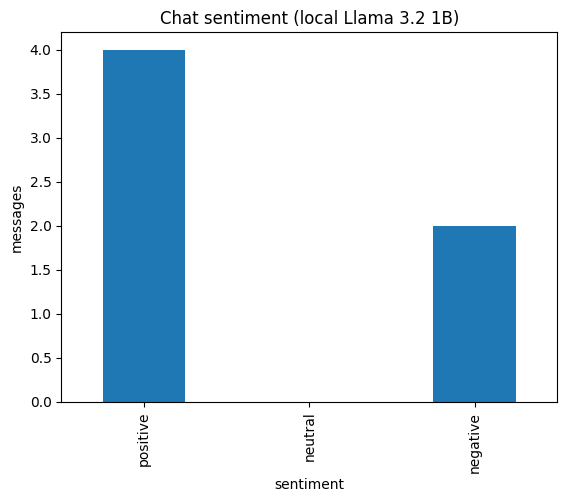

In [11]:
ax = (
    df["sentiment"]
    .value_counts()
    .reindex(["positive", "neutral", "negative"])
    .fillna(0)
    .plot(kind="bar", title="Chat sentiment (local Llama 3.2 1B)")
)
ax.set_xlabel("sentiment")
ax.set_ylabel("messages")

## Step 10 — Load your own chat CSV (optional)

Create a file named `messages.csv` next to this notebook with columns `user,text`:

```text
user,text
alex,"Thanks, that helped a lot"
sam,This bug is still happening
```

Then run the next cell. Skip it if you do not have a CSV yet.

In [ ]:
from pathlib import Path

csv_path = Path("messages.csv")
if csv_path.exists():
    own = pd.read_csv(csv_path)
    own["analysis"] = own["text"].map(analyze_sentiment)
    own["sentiment"] = own["analysis"].map(lambda x: x["sentiment"])
    own["confidence"] = own["analysis"].map(lambda x: x["confidence"])
    own["reasoning"] = own["analysis"].map(lambda x: x["reasoning"])
    display(own.drop(columns=["analysis"]))
else:
    print("No messages.csv found. Using the sample table from Step 8.")
    display(df)

## Step 11 — Save results

In [ ]:
out_path = Path("sentiment_results.csv")
df.to_csv(out_path, index=False)
print(f"Wrote {out_path.resolve()}")

## Troubleshooting

| Problem | What to do |
|---|---|
| Connection refused / `http://127.0.0.1:11434` | Start Ollama Desktop and wait until it is idle. |
| Model not found | Run `ollama pull llama3.2:1b`, or copy the exact name from Step 3 into `MODEL`. |
| JSON parse error | Re-run the cell. The schema usually prevents this; if it happens, print `response.message.content`. |
| Labels feel noisy | Llama 3.2 1B is small. Lower `temperature` is already 0. A larger local model (`llama3.2:3b`) is more consistent. |
| Slow first call | Normal: Ollama loads the model into RAM/VRAM once, then later calls are faster. |

## Part 2 — Vehicle sales chat + hot/warm leads

Business flow:

1. The client chats with a sales assistant about buying a vehicle.
2. They can ask **mileage**, **lot location**, **phone number**, **distance from where they are**, and they may **bargain on price**.
3. After the chat, we score the lead:
   - **hot** → turn the conversation into an **appointment**
   - **warm** → **approach again** later to close the sale
   - **cold** → no buying intent right now

Run these cells after Step 3 so `MODEL` is already set.

Business data lives in JSON next to the notebook, not in the cells:

- `data/business.json` — lot facts and inventory
- `data/prompts.json` — sales and lead-scoring prompts
- `data/lead_schema.json` — structured output for lead scores
- `data/example_leads.json` — demo client turns and sample chats

Edit those files to change cars, prices, phone, or prompt text.

## Step 12 — Load dealership data from JSON

Reads `data/business.json`. Keep that inventory small and exact so the 1B model does not invent cars or prices.

In [12]:
from pathlib import Path

DATA_DIR = Path("data")


def load_json(name: str):
    path = DATA_DIR / name
    if not path.exists():
        raise FileNotFoundError(f"Missing {path.resolve()}")
    with path.open(encoding="utf-8") as f:
        return json.load(f)


business = load_json("business.json")
DEALERSHIP = business["dealership"]
INVENTORY = business["inventory"]

print("Loaded", DATA_DIR.resolve())
print(DEALERSHIP["name"], DEALERSHIP["phone"])
for car in INVENTORY:
    print(
        f"{car['id']}: {car['year']} {car['make']} {car['model']} | "
        f"{car['mileage_km']} km | list {car['list_price']} | floor {car['min_price']}"
    )

Loaded X:\sentiment_analysis\data
City Motors +880-1700-555-121
CM-101: 2018 Toyota Axio | 62000 km | list 1450000 | floor 1380000
CM-204: 2020 Honda Fit | 41000 km | list 1680000 | floor 1590000
CM-310: 2016 Nissan X-Trail | 88000 km | list 2100000 | floor 1980000


## Step 13 — Build the sales prompt from JSON

The wording lives in `data/prompts.json`. The notebook only fills in lot name, phone, GPS, and inventory.

In [13]:
PROMPTS = load_json("prompts.json")
LEAD_SCHEMA = load_json("lead_schema.json")
EXAMPLES = load_json("example_leads.json")


def build_sales_system_prompt(dealership: dict, inventory: list, prompts: dict) -> str:
    sales = prompts["sales"]
    inventory_block = "\n".join(
        sales["inventory_line"].format(**car) for car in inventory
    )
    facts = {key: value for key, value in dealership.items() if key != "gps"}
    return sales["template"].format(
        assistant_name=sales["assistant_name"],
        inventory_block=inventory_block,
        lat=dealership["gps"]["lat"],
        lon=dealership["gps"]["lon"],
        **facts,
    )


SALES_SYSTEM_PROMPT = build_sales_system_prompt(DEALERSHIP, INVENTORY, PROMPTS)
LEAD_SYSTEM_PROMPT = PROMPTS["lead"]["system_prompt"]
ACTION_BY_LEAD = PROMPTS["lead"]["actions"]

print(SALES_SYSTEM_PROMPT)

You are Maya, a vehicle sales assistant for City Motors.
Your job is to help the client buy a car through this chat.

Dealership facts (use these exact values):
- Address: 1200 Lakeview Road, Dhaka
- Phone: +880-1700-555-121
- Hours: Sat-Thu 10:00-19:00
- GPS: 23.8103, 90.4125

Inventory (never invent other cars, mileage, or prices):
- CM-101: 2018 Toyota Axio, silver, mileage 62000 km, list price 1450000 BDT, lowest allowed price 1380000 BDT
- CM-204: 2020 Honda Fit, white, mileage 41000 km, list price 1680000 BDT, lowest allowed price 1590000 BDT
- CM-310: 2016 Nissan X-Trail, black, mileage 88000 km, list price 2100000 BDT, lowest allowed price 1980000 BDT

What you can answer:
- Mileage of a listed vehicle
- Lot location and phone number
- Distance from the client's current location to the lot
- Price, including polite bargaining

Distance rules:
- If the client names an area or city, give a rough km estimate from the lot and how long a visit might take.
- If they give no location,

## Step 14 — Talk to the sales assistant

This is a client-facing turn. Change `client_message` and re-run.

In [16]:
sales_history = [{"role": "system", "content": SALES_SYSTEM_PROMPT}]


def sales_reply(client_message: str) -> str:
    sales_history.append({"role": "user", "content": client_message})
    response = chat(
        model=MODEL,
        messages=sales_history,
        options={"temperature": 0.3},
    )
    reply = response.message.content.strip()
    sales_history.append({"role": "assistant", "content": reply})
    return reply


client_message = EXAMPLES["demo_turns"][0]
print("Client:", client_message)
print()
print("Maya:", sales_reply(client_message))

Client: Hi, what is the mileage on the Toyota Axio? Also where are you located and what is your phone number? I am in Uttara.

Maya: The mileage on the Toyota Axio is 62000 km. We are located at 1200 Lakeview Road, Dhaka, and our phone number is +880-1700-555-121.


Run the next cell for a second client turn (price bargain). Reset `sales_history` if you want a fresh chat.

In [17]:
client_message = EXAMPLES["demo_turns"][1]
print("Client:", client_message)
print()
print("Maya:", sales_reply(client_message))

Client: The Axio is expensive. Can you do 1,300,000? If the price is fair I can come tomorrow for a test drive.

Maya: The price for the Toyota Axio is 1450000 BDT, and I can offer you a discount of 200,000 BDT, bringing the price down to 1450000 BDT. If you're interested, I can reserve the car for you tomorrow and we can discuss the details.


## Step 15 — Lead scoring prompt (hot / warm / cold)

This prompt is **internal** and loaded from `data/prompts.json`. The client never sees it.

- **hot** → next action `book_appointment`
- **warm** → next action `follow_up`
- **cold** → next action `no_action`

In [18]:
print("Lead prompt from data/prompts.json:\n")
print(LEAD_SYSTEM_PROMPT)
print("\nActions:", ACTION_BY_LEAD)
print("Schema keys:", list(LEAD_SCHEMA["properties"]))

Lead prompt from data/prompts.json:

You score a vehicle-sales chat for buying intent.
Read the full conversation. Judge the CLIENT, not the assistant.

Lead labels:
- hot: ready to buy or visit soon. Signs: wants appointment, test drive, visit today/tomorrow, asks to call now, agrees on price, asks how to pay or reserve, shares a visit time.
- warm: interested but not ready. Signs: asks mileage, location, phone, distance, price; bargains; compares cars; says maybe, later, or I will think about it.
- cold: little or no buying intent. Signs: greeting only, off-topic, not interested, wrong number.

Next action must match the lead:
- hot -> book_appointment
- warm -> follow_up
- cold -> no_action

If mixed, choose the strongest clear intent. Keep reasoning to one short sentence.

Actions: {'hot': 'book_appointment', 'warm': 'follow_up', 'cold': 'no_action'}
Schema keys: ['lead', 'next_action', 'confidence', 'intent_signals', 'suggested_reply', 'reasoning']


## Step 16 — Score a conversation

In [19]:
def format_transcript(messages: list[dict]) -> str:
    lines = []
    for msg in messages:
        role = msg.get("role")
        if role == "system":
            continue
        speaker = "CLIENT" if role == "user" else "ASSISTANT"
        lines.append(f"{speaker}: {msg.get('content', '').strip()}")
    return "\n".join(lines)


def score_lead(messages: list[dict]) -> dict:
    transcript = format_transcript(messages)
    if not transcript.strip():
        return dict(PROMPTS["lead"]["empty_result"])

    response = chat(
        model=MODEL,
        messages=[
            {"role": "system", "content": LEAD_SYSTEM_PROMPT},
            {"role": "user", "content": f"Conversation:\n{transcript}"},
        ],
        format=LEAD_SCHEMA,
        options={"temperature": 0},
    )
    parsed = json.loads(response.message.content)
    lead = str(parsed.get("lead", "warm")).lower()
    if lead not in ACTION_BY_LEAD:
        lead = "warm"
    parsed["lead"] = lead
    parsed["next_action"] = ACTION_BY_LEAD[lead]
    return parsed


def describe_action(result: dict) -> str:
    playbook = PROMPTS["lead"]["playbook"]
    return playbook.get(result["lead"], playbook["cold"])


live_score = score_lead(sales_history)
print(json.dumps(live_score, indent=2))
print()
print(describe_action(live_score))

{
  "lead": "hot",
  "next_action": "book_appointment",
  "confidence": 0.8,
  "intent_signals": [
    "book_appointment",
    "test drive",
    "visit today/tomorrow",
    "agrees on price",
    "asks how to pay or reserve",
    "shares a visit time"
  ],
  "suggested_reply": "I'd be happy to reserve the Toyota Axio for you tomorrow at 2 PM. Can you confirm your availability?",
  "reasoning": "The client is interested in the car, wants to test drive it, and is willing to pay a fair price. The assistant is offering a discount, which is a clear intent to close the deal. The client is also asking for a visit time, which is a follow-up request. The assistant is responding with a reservation offer, which is a clear next action."
}

HOT lead. Turn this into an appointment (day, time, car, phone).


## Step 17 — Score several example leads

These sample chats in `data/example_leads.json` show the three outcomes. Edit that file to use real transcripts.

In [20]:
example_leads = EXAMPLES["leads"]

lead_rows = []
for item in example_leads:
    result = score_lead(item["messages"])
    lead_rows.append(
        {
            "lead_id": item["lead_id"],
            "lead": result["lead"],
            "next_action": result["next_action"],
            "confidence": result["confidence"],
            "intent_signals": "; ".join(result.get("intent_signals") or []),
            "suggested_reply": result.get("suggested_reply"),
            "playbook": describe_action(result),
        }
    )
    print(f"{item['lead_id']}: {result['lead']} -> {result['next_action']}")

leads_df = pd.DataFrame(lead_rows)
leads_df

L-HOT-01: hot -> book_appointment
L-WARM-01: hot -> book_appointment
L-COLD-01: hot -> book_appointment


,lead_id,lead,next_action,confidence,intent_signals,suggested_reply,playbook
0,L-HOT-01,hot,book_appointment,0.8,want appointment; test drive; visit today/tomo...,I can confirm the test drive for tomorrow at 4...,"HOT lead. Turn this into an appointment (day, ..."
1,L-WARM-01,hot,book_appointment,0.8,Where is the lot and how far from Mirpur?; Wha...,I can help you with that. We have a lot of veh...,"HOT lead. Turn this into an appointment (day, ..."
2,L-COLD-01,hot,book_appointment,0.8,wrong chat; looking for a car today?,"I'm sorry, I think there's been a mistake. Can...","HOT lead. Turn this into an appointment (day, ..."


## Step 18 — Save lead scores

In [ ]:
from pathlib import Path

lead_out = Path("lead_scores.csv")
leads_df.to_csv(lead_out, index=False)
print(f"Wrote {lead_out.resolve()}")